In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
import os

# Create the folder on Desktop (if it doesn't exist)
os.makedirs('/Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor', exist_ok=True)

# Move into it
os.chdir('/Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor')

# Confirm it worked
print("You are now in:", os.getcwd())

You are now in: /Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor


In [3]:
drug = pd.read_csv('faers_ascii_2026q1/ASCII/DRUG26Q1.txt', 
                   sep='$', 
                   encoding='latin-1',
                   on_bad_lines='skip')

print(drug.shape)
print(drug.head())

(1703210, 20)
    primaryid    caseid  drug_seq role_cod               drugname  \
0  1001678127  10016781         1       PS            SANDOSTATIN   
1  1001678127  10016781         2       SS            SANDOSTATIN   
2  1001678127  10016781         3       SS            SANDOSTATIN   
3  1001678127  10016781         4       SS  SANDOSTATIN LAR DEPOT   
4  1001678127  10016781         5       SS  SANDOSTATIN LAR DEPOT   

              prod_ai  val_vbm          route  \
0  OCTREOTIDE ACETATE        1   Subcutaneous   
1  OCTREOTIDE ACETATE        1  Intramuscular   
2  OCTREOTIDE ACETATE        1  Intramuscular   
3  OCTREOTIDE ACETATE        1  Intramuscular   
4  OCTREOTIDE ACETATE        1  Intramuscular   

                                 dose_vbm  cum_dose_chr cum_dose_unit dechal  \
0  UNK, TID (cont 02 weeks post 01st LAR)           NaN           NaN      Y   
1                              20 mg, QMO           NaN           NaN      Y   
2                              20 mg

In [5]:
import sqlite3

# Create a database file inside your project folder
conn = sqlite3.connect('faers.db')

# Load all 7 files into the database as tables
import pandas as pd

files = {
    'drug': 'faers_ascii_2026q1/ASCII/DRUG26Q1.txt',
    'reac': 'faers_ascii_2026q1/ASCII/REAC26Q1.txt',
    'demo': 'faers_ascii_2026q1/ASCII/DEMO26Q1.txt',
    'outc': 'faers_ascii_2026q1/ASCII/OUTC26Q1.txt',
    'indi': 'faers_ascii_2026q1/ASCII/INDI26Q1.txt',
    'ther': 'faers_ascii_2026q1/ASCII/THER26Q1.txt',
    'rpsr': 'faers_ascii_2026q1/ASCII/RPSR26Q1.txt',
}

for table_name, filepath in files.items():
    print(f'Loading {table_name}...')
    df = pd.read_csv(filepath, sep='$', encoding='latin-1', on_bad_lines='skip')
    df.to_sql(table_name, conn, if_exists='replace', index=False)
    print(f'Done! {len(df)} rows loaded into {table_name}')

print('\nAll files loaded into faers.db!')

Loading drug...
Done! 1703210 rows loaded into drug
Loading reac...
Done! 1330675 rows loaded into reac
Loading demo...


/var/folders/xb/wf8nwlrx11x4bmzx3wcd0yzw0000gn/T/ipykernel_21217/4241863155.py:21: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, sep='$', encoding='latin-1', on_bad_lines='skip')


Done! 397224 rows loaded into demo
Loading outc...
Done! 291580 rows loaded into outc
Loading indi...
Done! 1139940 rows loaded into indi
Loading ther...
Done! 404946 rows loaded into ther
Loading rpsr...
Done! 11426 rows loaded into rpsr

All files loaded into faers.db!


In [6]:
query = """
SELECT drugname, COUNT(*) as total_reports
FROM drug
GROUP BY drugname
ORDER BY total_reports DESC
LIMIT 10
"""

result = pd.read_sql_query(query, conn)
print(result)

        drugname  total_reports
0       DUPIXENT          42951
1       ZEPBOUND          26791
2       MOUNJARO          22069
3     PREDNISONE          20725
4   METHOTREXATE          17637
5         TYMLOS          16788
6      RITUXIMAB          13891
7      INFLECTRA          13509
8  ACETAMINOPHEN          13231
9        ACTEMRA          12163


In [7]:
query = """
SELECT pt, COUNT(*) as total_reports
FROM reac
GROUP BY pt
ORDER BY total_reports DESC
LIMIT 10
"""

result = pd.read_sql_query(query, conn)
print(result)

                            pt  total_reports
0                Off label use          27774
1             Drug ineffective          22442
2  Product dose omission issue          19786
3                       Nausea          17649
4                      Fatigue          17433
5                    Diarrhoea          15457
6                        Death          14200
7                     Headache          14107
8                     Pruritus          11615
9                         Pain          11038


In [8]:
query = """
SELECT d.drugname, r.pt, COUNT(*) as total_reports
FROM drug d
JOIN reac r ON d.primaryid = r.primaryid
WHERE d.drugname = 'IBUPROFEN'
GROUP BY d.drugname, r.pt
ORDER BY total_reports DESC
LIMIT 10
"""

result = pd.read_sql_query(query, conn)
print(result)

    drugname                pt  total_reports
0  IBUPROFEN   Nasopharyngitis            552
1  IBUPROFEN           Fatigue            498
2  IBUPROFEN            Nausea            495
3  IBUPROFEN  Drug ineffective            493
4  IBUPROFEN          Dyspnoea            477
5  IBUPROFEN     Off label use            472
6  IBUPROFEN     Muscle spasms            444
7  IBUPROFEN              Pain            403
8  IBUPROFEN          Headache            389
9  IBUPROFEN          Wheezing            382


In [9]:
query = """
SELECT d1.drugname as drug1, d2.drugname as drug2, r.pt, COUNT(*) as total_reports
FROM drug d1
JOIN drug d2 ON d1.primaryid = d2.primaryid
JOIN reac r ON d1.primaryid = r.primaryid
WHERE d1.drugname = 'IBUPROFEN'
AND d2.drugname = 'LISINOPRIL'
GROUP BY d1.drugname, d2.drugname, r.pt
ORDER BY total_reports DESC
LIMIT 10
"""

result = pd.read_sql_query(query, conn)
print(result)

       drug1       drug2                        pt  total_reports
0  IBUPROFEN  LISINOPRIL          Drug ineffective            246
1  IBUPROFEN  LISINOPRIL                Discomfort            242
2  IBUPROFEN  LISINOPRIL    Helicobacter infection            237
3  IBUPROFEN  LISINOPRIL                  Dyspnoea            235
4  IBUPROFEN  LISINOPRIL                   Fatigue            234
5  IBUPROFEN  LISINOPRIL            Joint swelling            234
6  IBUPROFEN  LISINOPRIL  Hepatic enzyme increased            230
7  IBUPROFEN  LISINOPRIL                 Pemphigus            230
8  IBUPROFEN  LISINOPRIL               Glossodynia            227
9  IBUPROFEN  LISINOPRIL            Hand deformity            227


In [12]:
query = """
SELECT d3.drugname as drug3, d4.drugname as drug4, r.pt, COUNT(*) as total_reports
FROM drug d3
JOIN drug d4 ON d3.primaryid = d4.primaryid
JOIN reac r ON d3.primaryid = r.primaryid
WHERE d3.drugname = 'PREDNISONE'
AND d4.drugname = 'METHOTREXATE'
GROUP BY d3.drugname, d4.drugname, r.pt
ORDER BY total_reports DESC
LIMIT 5
"""
result = pd.read_sql_query(query, conn)
print(result)

        drug3         drug4                             pt  total_reports
0  PREDNISONE  METHOTREXATE                  Off label use          78361
1  PREDNISONE  METHOTREXATE  Intentional product use issue          71874
2  PREDNISONE  METHOTREXATE               Drug ineffective          69173
3  PREDNISONE  METHOTREXATE               Drug intolerance          66610
4  PREDNISONE  METHOTREXATE           Rheumatoid arthritis          64125


In [13]:
query = """
SELECT sex, COUNT (*) as total_num
From demo
GROUP BY sex
ORDER BY total_num DESC
LIMIT 5
"""
result = pd.read_sql_query(query, conn)
print(result)

    sex  total_num
0     F     198072
1     M     123719
2  None      75433


In [14]:
query = """ 
SELECT AVG(age) from demo
"""
result = pd.read_sql_query(query, conn)
print(result)

    AVG(age)
0  54.272893


In [15]:
query = """
SELECT AVG(demo.age) as average_of_age, demo.sex as gender
FROM drug d5
JOIN demo ON d5.primaryid = demo.primaryid
WHERE d5.drugname = 'IBUPROFEN'
GROUP BY demo.sex
"""
result = pd.read_sql_query(query, conn)
print(result)


   average_of_age gender
0       45.450450   None
1       47.568480      F
2       51.484545      M


In [16]:
query = """
SELECT COUNT(DISTINCT drugname) as unique_drugs
FROM drug
"""
result = pd.read_sql_query(query, conn)
print("Total unique drug names:", result['unique_drugs'][0])

Total unique drug names: 32718


In [17]:
query = """
SELECT DISTINCT drugname 
FROM drug 
ORDER BY drugname
LIMIT 20
"""
result = pd.read_sql_query(query, conn)
print(result)

                                             drugname
0                                                None
1                                  !Magnesium citrate
2                                  #ODIUM BICARBONATE
3                                 (-)-METHAMPHETAMINE
4   (3+N) pegylated recombinant Human granulocyte ...
5         (BREO ELLIPTA) 100-25 mcg/dose dsdv inhaler
6        (Clinical)(Basic) Calcium folinate injection
7                                    (Cyclosporine A)
8                                          (DULCOLAX)
9                                           (LAMICTAL
10                                            (MIRALA
11                                          (NuvaRing
12        (S-1 [tegafur/gimeracil/oteracil potassium)
13        (S-1 [tegafur/gimeracil/oteracil potassium]
14                               (Spiriva) Tiotropium
15         ,Acetaminophen 500 mg tab,Furosemide 20 mg
16                                ,BREZTRI AEROSPHERE
17                          

In [ ]:
import re

drug = "!Magnesium citrate"
cleaned = re.sub(r'^[^a-zA-Z]+', '', drug)
print(cleaned)

In [ ]:
import re

def clean_drug_name(name):
    # Step 1: Handle None/missing values
    if name is None:
        return None
    
    # Step 2: Remove special characters from the start
    name = re.sub(r'^[^a-zA-Z]+', '', name)
    
    # Step 3: Remove parentheses and their contents
    name = re.sub(r'\(.*?\)', '', name)
    
    # Step 4: Remove dosage information
    name = re.sub(r'\d+\s*mg|\d+\s*mcg|\d+\s*ml', '', name, flags=re.IGNORECASE)
    
    # Step 5: Lowercase everything
    name = name.lower()

    name = re.sub(r'[()]', '', name)

    name = re.sub(r'\s+', ' ', name)

    # Step 6: Remove extra spaces
    name = name.strip()
    
    return name

# Test it on our messy examples
test_names = [
    '!Magnesium citrate',
    '#ODIUM BICARBONATE',
    '(DULCOLAX)',
    ',Acetaminophen 500 mg tab',
    '-1GABAPENTIN CAP 300MG',
    '.?Ferrous sulfate'
]

for name in test_names:
    print(f"{name} → {clean_drug_name(name)}")

In [ ]:
# Get all unique drug names
query = "SELECT DISTINCT drugname FROM drug"
unique_drugs = pd.read_sql_query(query, conn)

# Apply our cleaning function to every drug name
unique_drugs['cleaned_name'] = unique_drugs['drugname'].apply(clean_drug_name)

# See the results
print(f"Total unique drugs: {len(unique_drugs)}")
print(unique_drugs.head(20))

In [ ]:
# Show rows where the name actually changed
changed = unique_drugs[unique_drugs['drugname'] != unique_drugs['cleaned_name']]
print(f"Names that were changed: {len(changed)}")
print(changed.head(20))

In [ ]:
# Show only names that had special characters cleaned
interesting = unique_drugs[
    unique_drugs['drugname'].str.contains(r'^[^a-zA-Z]', regex=True, na=False)
]
print(f"Names with special characters at start: {len(interesting)}")
print(interesting.head(20))

In [ ]:
conn.close()

In [ ]:
import sqlite3
import pandas as pd
import os
import re

os.chdir('/Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor')
conn = sqlite3.connect('faers.db')
print("Connected!")

In [ ]:
drug_name = "ibuprofen\\lisinopril\\aspirin"

result = drug_name.split("\\")

print(result)

In [ ]:
import re

drug_name = "ibuprofen\\lisinopril;aspirin,paracetamol"

result = re.split(r'[\\;,]', drug_name)

print(result)

In [ ]:
# Get all drugs from the database
query = "SELECT primaryid, drugname FROM drug"
drug_df = pd.read_sql_query(query, conn)

print(f"Rows before splitting: {len(drug_df)}")

# Split multi-drug cells into separate rows
split_rows = []

for _, row in drug_df.iterrows():
    if row['drugname'] is None:
        continue
    
    # Split on \, ; or ,
    names = re.split(r'[\\;,]', str(row['drugname']))
    
    # Create a new row for each drug found
    for name in names:
        cleaned = clean_drug_name(name)
        if cleaned and len(cleaned) > 1:
            split_rows.append({
                'primaryid': row['primaryid'],
                'drugname_clean': cleaned
            })

# Turn into a dataframe
drug_clean = pd.DataFrame(split_rows)

print(f"Rows after splitting: {len(drug_clean)}")
print(drug_clean.head(10))

In [ ]:
# Remove duplicate rows
drug_clean = drug_clean.drop_duplicates(subset=['primaryid', 'drugname_clean'])

print(f"Rows after removing duplicates: {len(drug_clean)}")
print(drug_clean.head(10))

In [ ]:
drug_clean.to_sql('drug_clean', conn, if_exists='replace', index=False)
print("Saved to database!")

# Verify it saved correctly
query = "SELECT COUNT(*) as total FROM drug_clean"
result = pd.read_sql_query(query, conn)
print(f"Rows in database: {result['total'][0]}")

In [ ]:
def get_rxnorm_name(drug_name):
    url = f"https://rxnav.nlm.nih.gov/REST/drugs.json?name={drug_name}"
    response = requests.get(url)
    data = response.json()
    
    try:
        concepts = data['drugGroup']['conceptGroup']
        for group in concepts:
            if 'conceptProperties' in group:
                full_name = group['conceptProperties'][0]['name'].lower()
                # Remove dosage and brand name in brackets
                full_name = re.sub(r'\d+\s*mg.*', '', full_name)
                full_name = re.sub(r'\[.*?\]', '', full_name)
                full_name = full_name.strip()
                return full_name
    except:
        return None
    
    return None

# Test with a few drugs
test_drugs = ['crestor', 'advil', 'tylenol', 'aspirin']
for drug in test_drugs:
    result = get_rxnorm_name(drug)
    print(f"{drug} → {result}")

In [ ]:
def get_rxnorm_name(drug_name):
    url = f"https://rxnav.nlm.nih.gov/REST/drugs.json?name={drug_name}"
    response = requests.get(url)
    data = response.json()
    
    try:
        concepts = data['drugGroup']['conceptGroup']
        for group in concepts:
            if 'conceptProperties' in group:
                full_name = group['conceptProperties'][0]['name'].lower()
                full_name = re.sub(r'\d+\s*mg.*', '', full_name)
                full_name = re.sub(r'\[.*?\]', '', full_name)
                full_name = re.sub(r'\{.*?\}', '', full_name)
                full_name = re.sub(r'^[^a-zA-Z]+', '', full_name)
                full_name = re.sub(r'[()]', '', full_name)
                full_name = full_name.strip()
                return full_name
    except:
        return None
    
    return None

test_drugs = ['crestor', 'advil', 'tylenol', 'aspirin']
for drug in test_drugs:
    result = get_rxnorm_name(drug)
    print(f"{drug} → {result}")

In [ ]:
import time
import json

# Load previous progress if it exists
try:
    with open('rxnorm_map.json', 'r') as f:
        rxnorm_map = json.load(f)
    print(f"Loaded {len(rxnorm_map)} existing results")
except:
    rxnorm_map = {}
    print("Starting fresh")

query = "SELECT DISTINCT drugname_clean FROM drug_clean"
unique_drugs = pd.read_sql_query(query, conn)

for i, name in enumerate(unique_drugs['drugname_clean']):
    if name in rxnorm_map:
        continue  # Already done, skip it
    
    standard = get_rxnorm_name(name)
    rxnorm_map[name] = standard if standard else name
    
    # Save to disk every 500 drugs
    if i % 500 == 0:
        with open('rxnorm_map.json', 'w') as f:
            json.dump(rxnorm_map, f)
        print(f"Progress saved: {i}/{len(unique_drugs)}")
    
    time.sleep(0.1)

# Final save
with open('rxnorm_map.json', 'w') as f:
    json.dump(rxnorm_map, f)
print("Done!")

In [ ]:
import json

# Load the saved results
with open('rxnorm_map.json', 'r') as f:
    rxnorm_map = json.load(f)

print(f"Total mappings loaded: {len(rxnorm_map)}")

# Apply to drug_clean
drug_clean['drugname_standard'] = drug_clean['drugname_clean'].map(rxnorm_map)

# If RxNorm didn't find a standard name, keep the cleaned name
drug_clean['drugname_standard'] = drug_clean['drugname_standard'].fillna(drug_clean['drugname_clean'])

# Check the results
print(drug_clean[['drugname_clean', 'drugname_standard']].head(20))

In [ ]:
from difflib import SequenceMatcher

def is_similar_enough(original, standard, threshold=0.4):
    if standard is None:
        return False
    ratio = SequenceMatcher(None, original, standard).ratio()
    return ratio >= threshold

# Test it
print(is_similar_enough('aspirin', 'acetaminophen'))
print(is_similar_enough('aspirin', 'aspirin tablet'))
print(is_similar_enough('crestor', 'rosuvastatin calcium'))

In [ ]:
def apply_rxnorm_safely(original, standard):
    if standard is None:
        return original
    
    # Remove dosage fragments from standard name
    standard = re.sub(r'\b\d+\.?\d*\s*(ml|mg|mcg)?\b', '', standard)
    standard = re.sub(r'\s+', ' ', standard).strip()
    
    # If standard became empty or too short after cleaning, keep original
    if not standard or len(standard) < 2:
        return original
    
    # If clearly wrong (aspirin → acetaminophen type errors)
    # Check if original words appear anywhere in standard
    original_words = set(original.split())
    standard_words = set(standard.split())
    
    # If no words overlap AND similarity is very low, reject
    similarity = SequenceMatcher(None, original, standard).ratio()
    overlap = original_words & standard_words
    
    if similarity < 0.3 and not overlap:
        return original
        
    return standard

# Test it
test_cases = [
    ('aspirin', 'acetaminophen'),
    ('crestor', 'rosuvastatin calcium'),
    ('sandostatin', 'ml octreotide 0.'),
    ('afinitor', 'everolimus 7.'),
    ('abilify', 'ml aripiprazole'),
]

for original, standard in test_cases:
    result = apply_rxnorm_safely(original, standard)
    print(f"{original} → {result}")

In [ ]:
def apply_rxnorm_safely(original, standard):
    if standard is None:
        return original
    
    # Remove dosage fragments
    standard = re.sub(r'\b\d+\.?\d*\s*(ml|mg|mcg)?\b', '', standard)
    standard = re.sub(r'^\W+', '', standard)
    standard = re.sub(r'\s+', ' ', standard).strip()
    
    if not standard or len(standard) < 2:
        return original
    
    return standard

# Apply to entire dataframe
drug_clean['drugname_standard'] = drug_clean.apply(
    lambda row: apply_rxnorm_safely(
        row['drugname_clean'], 
        rxnorm_map.get(row['drugname_clean'])
    ), axis=1
)

# Check results
print(drug_clean[['drugname_clean', 'drugname_standard']].head(20))

In [ ]:
# Simply save drug_clean with both columns to database
# drugname_clean = our regex cleaned version (reliable)
# drugname_standard = RxNorm attempt (best effort)

# For modeling we'll use drugname_clean as our primary column
# It's already 90% of the way there

drug_clean.to_sql('drug_clean', conn, if_exists='replace', index=False)
print("Saved!")
print(f"Total rows: {len(drug_clean)}")
print(f"Unique clean names: {drug_clean['drugname_clean'].nunique()}")

In [18]:
query = """
SELECT pt, COUNT(*) as total
FROM reac
GROUP BY pt
ORDER BY total DESC
LIMIT 15
"""
result = pd.read_sql_query(query, conn)
print(result)

                             pt  total
0                 Off label use  27774
1              Drug ineffective  22442
2   Product dose omission issue  19786
3                        Nausea  17649
4                       Fatigue  17433
5                     Diarrhoea  15457
6                         Death  14200
7                      Headache  14107
8                      Pruritus  11615
9                          Pain  11038
10                     Vomiting  10896
11                     Dyspnoea  10748
12                    Dizziness  10654
13                         Rash  10112
14                   Arthralgia  10099


In [19]:
query = """
SELECT pt, COUNT(*) as total
FROM reac
GROUP BY pt
ORDER BY total DESC
LIMIT 50
"""
result = pd.read_sql_query(query, conn)
print(result)

                                                  pt  total
0                                      Off label use  27774
1                                   Drug ineffective  22442
2                        Product dose omission issue  19786
3                                             Nausea  17649
4                                            Fatigue  17433
5                                          Diarrhoea  15457
6                                              Death  14200
7                                           Headache  14107
8                                           Pruritus  11615
9                                               Pain  11038
10                                          Vomiting  10896
11                                          Dyspnoea  10748
12                                         Dizziness  10654
13                                              Rash  10112
14                                        Arthralgia  10099
15                              Conditio

In [22]:
noise = [
    'Off label use',
    'Drug ineffective', 
    'Product dose omission issue',
    'Product use in unapproved indication',
    'Inappropriate schedule of product administration',
    'Incorrect dose administered',
    'Product use issue',
    'Wrong technique in product usage process'
]

In [23]:
noise_str = "', '".join(noise)
print(noise_str)

Off label use', 'Drug ineffective', 'Product dose omission issue', 'Product use in unapproved indication', 'Inappropriate schedule of product administration', 'Incorrect dose administered', 'Product use issue', 'Wrong technique in product usage process


In [24]:
query = f"""
SELECT * FROM reac
WHERE pt NOT IN ('{noise_str}')
"""

In [25]:

reac_clean = pd.read_sql_query(query, conn)
print(f"Rows before: 1330675")
print(f"Rows after removing noise: {len(reac_clean)}")
print(reac_clean['pt'].value_counts().head(10))

Rows before: 1330675
Rows after removing noise: 1230152
pt
Nausea       17649
Fatigue      17433
Diarrhoea    15457
Death        14200
Headache     14107
Pruritus     11615
Pain         11038
Vomiting     10896
Dyspnoea     10748
Dizziness    10654
Name: count, dtype: int64


In [26]:
reac_clean.to_sql('reac_clean', conn, if_exists='replace', index=False)
print("Saved!")

Saved!


In [27]:
query = """
SELECT 
    COUNT(*) as total,
    SUM(CASE WHEN sex IS NULL THEN 1 ELSE 0 END) as missing_sex,
    SUM(CASE WHEN age IS NULL THEN 1 ELSE 0 END) as missing_age,
    SUM(CASE WHEN occr_country IS NULL THEN 1 ELSE 0 END) as missing_country
FROM demo
"""
result = pd.read_sql_query(query, conn)
print(result)

    total  missing_sex  missing_age  missing_country
0  397224        75433       151608            32170


In [28]:
query = """
SELECT 
    AVG(age) as mean_age,
    COUNT(*) as total
FROM demo
WHERE age IS NOT NULL
"""
result = pd.read_sql_query(query, conn)
print(result)

    mean_age   total
0  54.272893  245616


In [30]:
query = """
SELECT sex, COUNT(*) as total
FROM demo
WHERE sex IS NOT NULL
GROUP BY sex
ORDER BY total DESC
LIMIT 1
"""
result = pd.read_sql_query(query, conn)
print(result)

  sex   total
0   F  198072


In [33]:
demo_df = pd.read_sql_query("SELECT * FROM demo", conn)
demo_df['age'] = demo_df['age'].fillna(54)
demo_df['sex'] = demo_df['sex'].fillna('F')
demo_df['occr_country'] = demo_df['occr_country'].fillna('UNKNOWN')

In [34]:
print(demo_df.isnull().sum())

primaryid                0
caseid                   0
caseversion              0
i_f_code                 0
event_dt            229258
mfr_dt                   0
init_fda_dt              0
fda_dt                   0
rept_cod                 0
auth_num            358589
mfr_num              13334
mfr_sndr                 0
lit_ref             372405
age                      0
age_cod             151605
age_grp             265421
sex                      0
e_sub                    0
wt                  328133
wt_cod              328133
rept_dt                  0
to_mfr              384965
occp_cod            139395
reporter_country         4
occr_country             0
dtype: int64


In [35]:
demo_df.to_sql('demo_clean', conn, if_exists='replace', index=False)
print("Saved!")

Saved!


In [36]:
query = """
SELECT outc_cod, COUNT(*) as total
FROM outc
GROUP BY outc_cod
ORDER BY total DESC
"""
result = pd.read_sql_query(query, conn)
print(result)

  outc_cod   total
0       OT  158154
1       HO   80509
2       DE   30927
3       LT   13222
4       DS    5935
5       CA    1517
6       RI    1316


In [40]:
outcome_map = {
    'OT': 'Other',
    'HO': 'Hospitalization',
    'DE': 'Death',
    'LT': 'Life Threatening',
    'DS': 'Disability',
    'CA': 'Congenital Anomaly',
    'RI': 'Required Intervention'
}

In [43]:
outc_df = pd.read_sql_query("SELECT * FROM outc", conn)
print(outc_df.head())

    primaryid    caseid outc_cod
0  1001678127  10016781       OT
1   100293665  10029366       OT
2  1005762126  10057621       HO
3   100670805  10067080       OT
4   100716524  10071652       OT


In [44]:
outc_df['outcome'] = outc_df['outc_cod'].map(outcome_map)
print(outc_df.head(10))

    primaryid    caseid outc_cod          outcome
0  1001678127  10016781       OT            Other
1   100293665  10029366       OT            Other
2  1005762126  10057621       HO  Hospitalization
3   100670805  10067080       OT            Other
4   100716524  10071652       OT            Other
5  1007844154  10078441       OT            Other
6   101092286  10109228       OT            Other
7  1017130217  10171302       OT            Other
8  1017572234  10175722       OT            Other
9   101872822  10187282       DE            Death


In [45]:
outc_df.to_sql('outc_clean', conn, if_exists='replace', index=False)
print("Saved!")

Saved!


In [47]:
query = """
SELECT drug_clean.drugname_clean, reac_clean.pt
FROM drug_clean
JOIN reac_clean ON drug_clean.primaryid = reac_clean.primaryid
LIMIT 10
"""
result = pd.read_sql_query(query, conn)
print(result)

  drugname_clean                                 pt
0    sandostatin                     Abdominal pain
1    sandostatin                               Acne
2    sandostatin                            Anaemia
3    sandostatin                            Anxiety
4    sandostatin                         Arthralgia
5    sandostatin                   Balance disorder
6    sandostatin           Blood creatine increased
7    sandostatin  Blood pressure systolic increased
8    sandostatin                          Bone pain
9    sandostatin                         Bronchitis


In [48]:
query = """
SELECT drug_clean.drugname_clean, reac_clean.pt
FROM drug_clean
JOIN reac_clean ON drug_clean.primaryid = reac_clean.primaryid
"""
drug_reac = pd.read_sql_query(query, conn)
print(f"Total rows: {len(drug_reac)}")

Total rows: 9565856


In [49]:
# Total number of reports
total_reports = len(drug_reac)
print(f"Total reports: {total_reports}")

# How many times each reaction appears total
reaction_counts = drug_reac['pt'].value_counts().reset_index()
reaction_counts.columns = ['pt', 'reaction_total']

# How many times each drug appears total  
drug_counts = drug_reac['drugname_clean'].value_counts().reset_index()
drug_counts.columns = ['drugname_clean', 'drug_total']

print(reaction_counts.head())
print(drug_counts.head())

Total reports: 9565856
          pt  reaction_total
0    Fatigue          118718
1     Nausea          113399
2  Diarrhoea           99569
3   Headache           96902
4   Dyspnoea           89055
  drugname_clean  drug_total
0  acetaminophen      101415
1     prednisone      100146
2       dupixent       87248
3      rituximab       69779
4   methotrexate       62722


In [50]:
# Count how many times each drug-reaction pair appears together
pair_counts = drug_reac.groupby(['drugname_clean', 'pt']).size().reset_index()
pair_counts.columns = ['drugname_clean', 'pt', 'pair_count']

# Merge with drug totals and reaction totals
pair_counts = pair_counts.merge(drug_counts, on='drugname_clean')
pair_counts = pair_counts.merge(reaction_counts, on='pt')

# Add total reports
pair_counts['total'] = total_reports

# Calculate PRR
pair_counts['PRR'] = (pair_counts['pair_count'] / pair_counts['drug_total']) / \
                     (pair_counts['reaction_total'] / pair_counts['total'])

# Sort by strongest signals
pair_counts = pair_counts.sort_values('PRR', ascending=False)

print(f"Total drug-reaction pairs: {len(pair_counts)}")
print(pair_counts[['drugname_clean', 'pt', 'pair_count', 'PRR']].head(10))

Total drug-reaction pairs: 1692292
                            drugname_clean  \
638996                          fsme-immun   
456742                      dimethyl ether   
535472   equate vagicaine maximum strength   
154629                             babybig   
1528806              tuberculosis vaccines   
1114631              orajel kidstoothpaste   
288927                            ceprotin   
661347                             gliadel   
1301243                           rheumate   
1346590                       scholar rock   

                                          pt  pair_count           PRR  
638996            Vaccination site granuloma           1  4.782928e+06  
456742                  Device catching fire           1  4.782928e+06  
535472            Chemical burn of genitalia           1  4.782928e+06  
154629                Pseudomonas bronchitis           1  4.782928e+06  
1528806     False positive tuberculosis test           1  4.782928e+06  
1114631             

In [51]:
# Only keep pairs with at least 3 reports
reliable = pair_counts[pair_counts['pair_count'] >= 3]

# Only keep PRR above 2 (meaningful signal)
signals = reliable[reliable['PRR'] >= 2]

print(f"Reliable drug-reaction signals: {len(signals)}")
print(signals[['drugname_clean', 'pt', 'pair_count', 'PRR']].head(10))

Reliable drug-reaction signals: 253283
                          drugname_clean  \
99084                         aphiahsone   
933291                      melanotan ii   
690618               histamine phosphate   
1450659  technetium tc-99m medronate kit   
962665                       methoxsalen   
214641                               bss   
1301801                        rhophylac   
1519154                           trimeb   
909408                              maci   
402918         dalbavancin hydrochloride   

                                                     pt  pair_count  \
99084                          Ovarian cancer stage III           3   
933291                          Renal artery thrombosis           4   
690618              False negative investigation result           4   
1450659                   Radioisotope uptake increased           7   
962665                     Vogt-Koyanagi-Harada disease           4   
214641                  Toxic anterior segment syn

In [52]:
# Raise threshold to at least 10 reports and PRR above 2
strong_signals = pair_counts[
    (pair_counts['pair_count'] >= 10) & 
    (pair_counts['PRR'] >= 2)
]

strong_signals = strong_signals.sort_values('PRR', ascending=False)

print(f"Strong signals: {len(strong_signals)}")
print(strong_signals[['drugname_clean', 'pt', 'pair_count', 'PRR']].head(10))

Strong signals: 73800
                      drugname_clean                                 pt  \
214641                           bss    Toxic anterior segment syndrome   
1029967                      myoview         Radioisotope scan abnormal   
29729                    adstiladrin        Instillation site discharge   
1450624            technetium tc-99m         Radioisotope scan abnormal   
766766                      ioversol            Contrast encephalopathy   
359305                    combipatch                  Adhesive tape use   
674584                       gonal-f  Ovarian hyperstimulation syndrome   
1072972                    novoeight            Haemophilic arthropathy   
673427   gold bond original strength           Sarcomatoid mesothelioma   
651273                     ganirelix  Ovarian hyperstimulation syndrome   

         pair_count            PRR  
214641           12  162823.080851  
1029967          10   48361.253792  
29729            11   41822.104928  
1450

In [53]:
strong_signals.to_sql('drug_reaction_signals', conn, if_exists='replace', index=False)
print("Saved!")
print(f"Total signals saved: {len(strong_signals)}")

Saved!
Total signals saved: 73800


In [54]:
query = """
SELECT a.drugname_clean as drug1, 
       b.drugname_clean as drug2,
       a.pt as shared_reaction,
       a.PRR as drug1_prr,
       b.PRR as drug2_prr
FROM drug_reaction_signals a
JOIN drug_reaction_signals b ON a.pt = b.pt
WHERE a.drugname_clean < b.drugname_clean
LIMIT 10
"""
result = pd.read_sql_query(query, conn)
print(result)

                     drug1                          drug2  \
0                  myoview              technetium tc-99m   
1                  gonal-f                   progesterone   
2                ganirelix                        gonal-f   
3                ganirelix                   progesterone   
4  choriogonadotropin alfa                      ganirelix   
5  choriogonadotropin alfa                        gonal-f   
6  choriogonadotropin alfa                   progesterone   
7  lopinavir and ritonavir                      ritonavir   
8  lopinavir and ritonavir           tenofovir disoproxil   
9  lopinavir and ritonavir  tenofovir disoproxil fumarate   

                     shared_reaction     drug1_prr     drug2_prr  
0         Radioisotope scan abnormal  48361.253792  30581.381074  
1  Ovarian hyperstimulation syndrome  14993.504702    142.700244  
2  Ovarian hyperstimulation syndrome  14136.733005  14993.504702  
3  Ovarian hyperstimulation syndrome  14136.733005    142.70

In [55]:
query = """
SELECT a.drugname_clean as drug1, 
       b.drugname_clean as drug2,
       a.pt as shared_reaction,
       a.PRR as drug1_prr,
       b.PRR as drug2_prr
FROM drug_reaction_signals a
JOIN drug_reaction_signals b ON a.pt = b.pt
WHERE a.drugname_clean < b.drugname_clean
"""
drug_pairs = pd.read_sql_query(query, conn)
print(f"Total drug pairs: {len(drug_pairs)}")
print(drug_pairs.head())

Total drug pairs: 3766477
                     drug1              drug2  \
0                  myoview  technetium tc-99m   
1                  gonal-f       progesterone   
2                ganirelix            gonal-f   
3                ganirelix       progesterone   
4  choriogonadotropin alfa          ganirelix   

                     shared_reaction     drug1_prr     drug2_prr  
0         Radioisotope scan abnormal  48361.253792  30581.381074  
1  Ovarian hyperstimulation syndrome  14993.504702    142.700244  
2  Ovarian hyperstimulation syndrome  14136.733005  14993.504702  
3  Ovarian hyperstimulation syndrome  14136.733005    142.700244  
4  Ovarian hyperstimulation syndrome  12461.268352  14136.733005  


In [56]:
drug_pairs_agg = drug_pairs.groupby(['drug1', 'drug2']).agg(
    shared_reactions = ('shared_reaction', 'count'),
    avg_prr_drug1 = ('drug1_prr', 'mean'),
    avg_prr_drug2 = ('drug2_prr', 'mean')
).reset_index()

print(f"Unique drug pairs: {len(drug_pairs_agg)}")
print(drug_pairs_agg.head(10))

Unique drug pairs: 1029198
      drug1                     drug2  shared_reactions  avg_prr_drug1  \
0  abacavir          abacavir sulfate                36      12.697322   
1  abacavir                 abatacept                 3       5.031072   
2  abacavir               abemaciclib                 3       6.000674   
3  abacavir                   abilify                 1      80.002723   
4  abacavir       abiraterone acetate                 1       4.001262   
5  abacavir             acalabrutinib                 1       4.840790   
6  abacavir       acamprosate calcium                 1       2.252568   
7  abacavir  acebutolol hydrochloride                 2       5.077671   
8  abacavir               aceclofenac                 2       2.826353   
9  abacavir             acetaminophen                 1       7.172742   

   avg_prr_drug2  
0      13.585646  
1       2.567205  
2       3.304396  
3      20.665965  
4       6.161363  
5       2.001577  
6      25.336070  
7     

In [57]:
drug_pairs_agg['label'] = ((drug_pairs_agg['shared_reactions']>= 3) & ( (drug_pairs_agg['avg_prr_drug1'] > 2) & (drug_pairs_agg['avg_prr_drug2'] > 2))).astype(int)

In [58]:
print(drug_pairs_agg['label'].value_counts())

label
0    722909
1    306289
Name: count, dtype: int64


In [59]:
drug_pairs_agg.to_sql('drug_pairs', conn, if_exists='replace', index=False)
print("Saved!")


Saved!


In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Define features and label
X = drug_pairs_agg[['shared_reactions', 'avg_prr_drug1', 'avg_prr_drug2']]
y = drug_pairs_agg['label']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 823358
Testing samples: 205840


In [61]:
# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Evaluate on test set
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    144419
           1       1.00      1.00      1.00     61421

    accuracy                           1.00    205840
   macro avg       1.00      1.00      1.00    205840
weighted avg       1.00      1.00      1.00    205840



In [63]:
ddi = pd.read_csv('/Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor/ChCh-Miner_durgbank-chem-chem.tsv', 
                  sep='\t', 
                  header=None,
                  names=['drug1_id', 'drug2_id'])

print(f"Total interactions: {len(ddi)}")
print(ddi.head())

Total interactions: 48514
  drug1_id drug2_id
0  DB00862  DB00966
1  DB00575  DB00806
2  DB01242  DB08893
3  DB01151  DB08883
4  DB01235  DB01275


In [64]:
import requests

url = "https://go.drugbank.com/releases/5-1-9/downloads/all-drugbank-vocabulary"
response = requests.get(url)

with open('drugbank_vocabulary.csv', 'wb') as f:
    f.write(response.content)

print("Downloaded!")

Downloaded!


In [67]:
vocab = pd.read_csv('drugbank_vocabulary.csv', sep='\t')
print(vocab.columns.tolist())
print(vocab.head())

['<!DOCTYPE html><html lang="en"><head><script>']
  <!DOCTYPE html><html lang="en"><head><script>
0                                   //<![CDATA[
1    window.dataLayer = window.dataLayer || [];
2                        window.dataLayer.push(
3                           {"plus_user":false}
4                                            );


In [68]:
vocab = pd.read_csv('https://raw.githubusercontent.com/dhimmel/drugbank/gh-pages/data/drugbank.tsv', sep='\t')
print(vocab.columns.tolist())
print(vocab.head())

['drugbank_id', 'name', 'type', 'groups', 'atc_codes', 'categories', 'inchikey', 'inchi', 'description']
  drugbank_id                 name     type                    groups  \
0     DB00001            Lepirudin  biotech                  approved   
1     DB00002            Cetuximab  biotech                  approved   
2     DB00003         Dornase alfa  biotech                  approved   
3     DB00004  Denileukin diftitox  biotech  approved|investigational   
4     DB00005           Etanercept  biotech  approved|investigational   

  atc_codes                         categories inchikey inchi  \
0   B01AE02  Antithrombins|Fibrinolytic Agents      NaN   NaN   
1   L01XC06              Antineoplastic Agents      NaN   NaN   
2   R05CB13                            Enzymes      NaN   NaN   
3   L01XX29              Antineoplastic Agents      NaN   NaN   
4   L04AB01           Immunosuppressive Agents      NaN   NaN   

                                         description  
0  Lepirud

In [69]:
# Keep only id and name columns
vocab_small = vocab[['drugbank_id', 'name']]

# Map drug1 IDs to names
ddi = ddi.merge(vocab_small, left_on='drug1_id', right_on='drugbank_id')
ddi = ddi.rename(columns={'name': 'drug1_name'})
ddi = ddi.drop(columns=['drugbank_id'])

# Map drug2 IDs to names
ddi = ddi.merge(vocab_small, left_on='drug2_id', right_on='drugbank_id')
ddi = ddi.rename(columns={'name': 'drug2_name'})
ddi = ddi.drop(columns=['drugbank_id'])

print(f"Total interactions with names: {len(ddi)}")
print(ddi[['drug1_name', 'drug2_name']].head(10))

Total interactions with names: 40368
           drug1_name      drug2_name
0          Vardenafil     Telmisartan
1           Clonidine  Pentoxifylline
2        Clomipramine      Mirabegron
3         Desipramine      Perampanel
4              L-DOPA     Hydralazine
5  Interferon alfa-n3       Methadone
6            Caffeine     Deferasirox
7        Flurbiprofen   Acenocoumarol
8   Dextroamphetamine    Fluspirilene
9         Deferasirox       Tolvaptan


In [70]:
ddi['drug1_name'] = ddi['drug1_name'].str.lower()
ddi['drug2_name'] = ddi['drug2_name'].str.lower()

# Add label = 1 (these are all confirmed interactions)
ddi['label'] = 1

print(ddi.head())

  drug1_id drug2_id    drug1_name      drug2_name  label
0  DB00862  DB00966    vardenafil     telmisartan      1
1  DB00575  DB00806     clonidine  pentoxifylline      1
2  DB01242  DB08893  clomipramine      mirabegron      1
3  DB01151  DB08883   desipramine      perampanel      1
4  DB01235  DB01275        l-dopa     hydralazine      1


In [71]:
# Merge DrugBank interactions with our FAERS features
model_data = ddi.merge(
    drug_pairs_agg,
    left_on=['drug1_name', 'drug2_name'],
    right_on=['drug1', 'drug2'],
    how='inner'
)

print(f"Matched pairs: {len(model_data)}")
print(model_data.head())

Matched pairs: 3557
  drug1_id drug2_id      drug1_name       drug2_name  label_x           drug1  \
0  DB00396  DB00682    progesterone         warfarin        1    progesterone   
1  DB00673  DB08918      aprepitant  levomilnacipran        1      aprepitant   
2  DB00390  DB00986         digoxin   glycopyrrolate        1         digoxin   
3  DB00502  DB01367     haloperidol       rasagiline        1     haloperidol   
4  DB00741  DB01306  hydrocortisone   insulin aspart        1  hydrocortisone   

             drug2  shared_reactions  avg_prr_drug1  avg_prr_drug2  label_y  
0         warfarin                 3       3.576324       2.728882        1  
1  levomilnacipran                54       2.762092       3.145041        1  
2   glycopyrrolate                 5       3.443701       4.126965        1  
3       rasagiline                 1       9.372943      33.550060        0  
4   insulin aspart                 1       2.014709       4.787141        0  


In [72]:
# Keep only what we need
model_data = model_data[['drug1_name', 'drug2_name', 'shared_reactions', 
                          'avg_prr_drug1', 'avg_prr_drug2', 'label_x']]
model_data = model_data.rename(columns={'label_x': 'label'})

# Get negative examples - drug pairs in our FAERS data but NOT in DrugBank
ddi_pairs = set(zip(ddi['drug1_name'], ddi['drug2_name']))

negatives = drug_pairs_agg[
    ~drug_pairs_agg.apply(lambda r: (r['drug1'], r['drug2']) in ddi_pairs, axis=1)
].sample(n=3557, random_state=42)

negatives = negatives[['drug1', 'drug2', 'shared_reactions', 'avg_prr_drug1', 'avg_prr_drug2']]
negatives.columns = ['drug1_name', 'drug2_name', 'shared_reactions', 'avg_prr_drug1', 'avg_prr_drug2']
negatives['label'] = 0

# Combine positives and negatives
final_data = pd.concat([model_data, negatives], ignore_index=True)
print(f"Total samples: {len(final_data)}")
print(final_data['label'].value_counts())

Total samples: 7114
label
1    3557
0    3557
Name: count, dtype: int64


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Features and label
X = final_data[['shared_reactions', 'avg_prr_drug1', 'avg_prr_drug2']]
y = final_data['label']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.54      0.85      0.66       686
           1       0.70      0.33      0.45       737

    accuracy                           0.58      1423
   macro avg       0.62      0.59      0.56      1423
weighted avg       0.62      0.58      0.55      1423



In [74]:
from sklearn.ensemble import RandomForestClassifier
# Features and label
X = final_data[['shared_reactions', 'avg_prr_drug1', 'avg_prr_drug2']]
y = final_data['label']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.58      0.61      0.60       686
           1       0.62      0.60      0.61       737

    accuracy                           0.60      1423
   macro avg       0.60      0.60      0.60      1423
weighted avg       0.60      0.60      0.60      1423



In [75]:
final_data.to_sql('model_data', conn, if_exists='replace', index=False)
print("Saved!")
conn.close()

Saved!


In [76]:
import sqlite3
import pandas as pd
import os

os.chdir('/Users/HamadaSalimGTrd/Desktop/drug-interaction-predictor')
conn = sqlite3.connect('faers.db')
print("Connected!")

Connected!


In [77]:
import subprocess
subprocess.run(['pip', 'install', 'torch-geometric', 'torch', 'networkx'])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 3.6 MB/s  0:00:00m0:00:0100:01


CompletedProcess(args=['pip', 'install', 'torch-geometric', 'torch', 'networkx'], returncode=0)

In [78]:
import networkx as nx
import torch

# Load our interaction data
model_data = pd.read_sql_query("SELECT * FROM model_data", conn)
print(f"Total samples: {len(model_data)}")

# Get only the confirmed interactions (label = 1)
interactions = model_data[model_data['label'] == 1]
print(f"Confirmed interactions: {len(interactions)}")

Total samples: 7114
Confirmed interactions: 3557


In [79]:
# Create a graph
G = nx.Graph()

# Add edges for each confirmed interaction
for _, row in interactions.iterrows():
    G.add_edge(row['drug1_name'], row['drug2_name'])

print(f"Number of drugs (nodes): {G.number_of_nodes()}")
print(f"Number of interactions (edges): {G.number_of_edges()}")

Number of drugs (nodes): 544
Number of interactions (edges): 3557


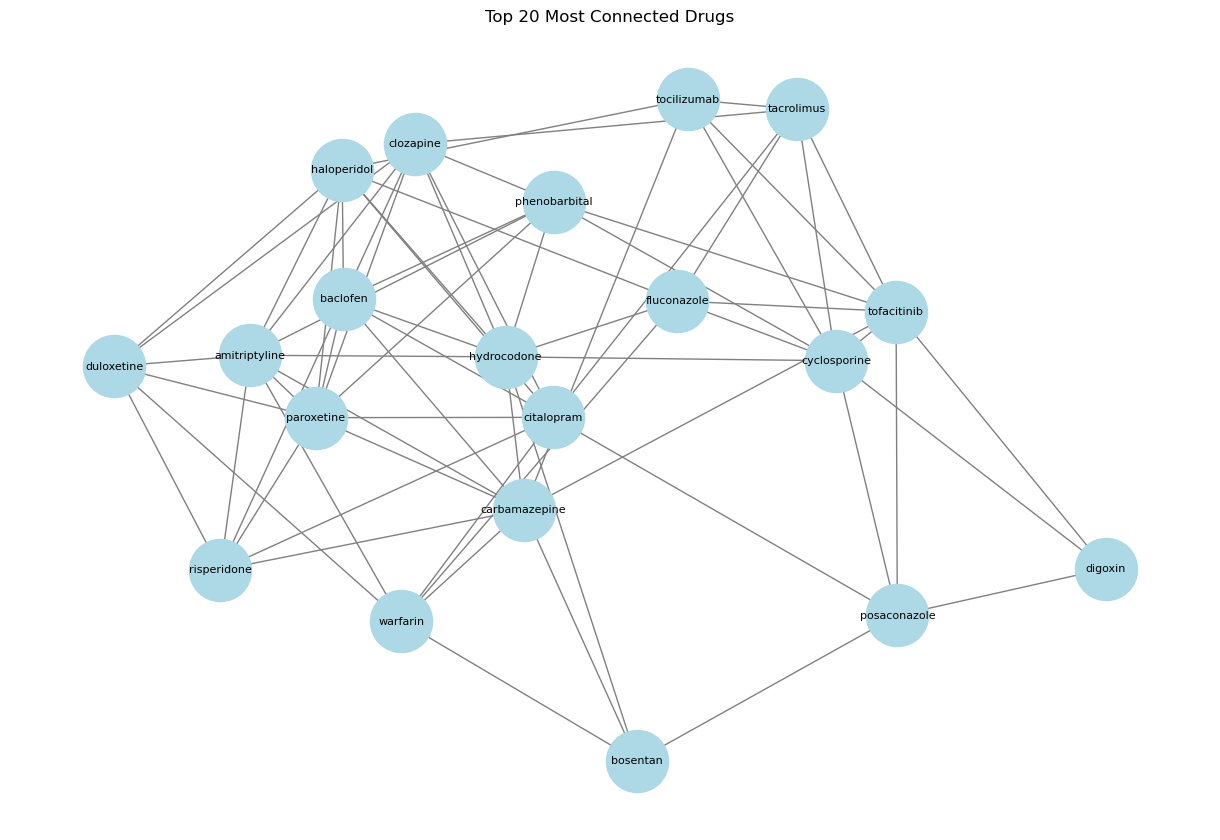

In [80]:
import matplotlib.pyplot as plt

# Take a small subgraph - just the top 20 most connected drugs
top_drugs = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:20]
top_drug_names = [drug for drug, degree in top_drugs]
subgraph = G.subgraph(top_drug_names)

# Draw it
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(subgraph, seed=42)
nx.draw(subgraph, pos, 
        with_labels=True, 
        node_color='lightblue',
        node_size=2000,
        font_size=8,
        edge_color='gray')
plt.title("Top 20 Most Connected Drugs")
plt.show()

In [81]:
import torch
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
import torch.nn.functional as F

print(f"PyTorch version: {torch.__version__}")
print("PyTorch Geometric loaded successfully!")

PyTorch version: 2.10.0
PyTorch Geometric loaded successfully!


In [82]:
# Create a mapping from drug name to a number
drug_names = list(G.nodes())
drug_to_idx = {drug: idx for idx, drug in enumerate(drug_names)}

print(f"Total drugs: {len(drug_names)}")
print(f"Example mapping: {drug_names[0]} → {drug_to_idx[drug_names[0]]}")

Total drugs: 544
Example mapping: progesterone → 0


In [83]:
# Build edge index
edge_index = []

for drug1, drug2 in G.edges():
    idx1 = drug_to_idx[drug1]
    idx2 = drug_to_idx[drug2]
    edge_index.append([idx1, idx2])
    edge_index.append([idx2, idx1])  # add both directions

edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
print(f"Edge index shape: {edge_index.shape}")

Edge index shape: torch.Size([2, 7114])


In [84]:
# Create node features
node_features = []

for drug in drug_names:
    # Get average PRR for this drug across all its interactions
    drug_data = model_data[
        (model_data['drug1_name'] == drug) | 
        (model_data['drug2_name'] == drug)
    ]
    
    avg_prr = drug_data['avg_prr_drug1'].mean() if len(drug_data) > 0 else 0
    avg_reactions = drug_data['shared_reactions'].mean() if len(drug_data) > 0 else 0
    degree = G.degree(drug)  # how many interactions this drug has
    
    node_features.append([avg_prr, avg_reactions, degree])

# Convert to tensor
x = torch.tensor(node_features, dtype=torch.float)
print(f"Node features shape: {x.shape}")
print(f"Example features for {drug_names[0]}: {x[0]}")

Node features shape: torch.Size([544, 3])
Example features for progesterone: tensor([11.6475,  3.0000,  7.0000])


In [85]:
# Create the graph data object
data = Data(x=x, edge_index=edge_index)

print(f"Graph summary:")
print(f"  Nodes: {data.num_nodes}")
print(f"  Edges: {data.num_edges}")
print(f"  Node features: {data.num_node_features}")

Graph summary:
  Nodes: 544
  Edges: 7114
  Node features: 3


In [96]:
from torch_geometric.transforms import RandomLinkSplit

transform = RandomLinkSplit(
    num_val=0.1,
    num_test=0.2,
    is_undirected=True,
    add_negative_train_samples=True,
)

train_data, val_data, test_data = transform(data)

print(f"Training edges: {train_data.edge_index.shape[1]}")
print(f"Validation edges: {val_data.edge_label_index.shape[1]}")
print(f"Test edges: {test_data.edge_label_index.shape[1]}")

Training edges: 4982
Validation edges: 710
Test edges: 1422


In [97]:
model = DrugGNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

def train():
    model.train()
    optimizer.zero_grad()
    z = model.encode(data.x, train_data.edge_index)
    loss = model.decode(z, train_data.edge_label_index)
    loss = F.binary_cross_entropy_with_logits(loss, train_data.edge_label)
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate(eval_data):
    model.eval()
    z = model.encode(data.x, train_data.edge_index)
    scores = torch.sigmoid(model.decode(z, eval_data.edge_label_index))
    return roc_auc_score(eval_data.edge_label.numpy(), scores.numpy())

for epoch in range(500):
    loss = train()
    if epoch % 50 == 0:
        val_auc = evaluate(val_data)
        print(f"Epoch {epoch}: Loss = {loss:.4f}, Val AUC = {val_auc:.4f}")

# Final honest evaluation on test set
test_auc = evaluate(test_data)
print(f"\nFinal Test AUC: {test_auc:.4f}")

Epoch 0: Loss = 145.0039, Val AUC = 0.5043
Epoch 50: Loss = 0.6162, Val AUC = 0.7778
Epoch 100: Loss = 0.5780, Val AUC = 0.7816
Epoch 150: Loss = 0.5671, Val AUC = 0.7934
Epoch 200: Loss = 0.5584, Val AUC = 0.8054
Epoch 250: Loss = 0.5513, Val AUC = 0.8096
Epoch 300: Loss = 0.5463, Val AUC = 0.8106
Epoch 350: Loss = 0.5431, Val AUC = 0.8108
Epoch 400: Loss = 0.5408, Val AUC = 0.8100
Epoch 450: Loss = 0.5390, Val AUC = 0.8089

Final Test AUC: 0.7881


In [98]:
# Reinitialize model
model = DrugGNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

best_val_auc = 0
best_epoch = 0

for epoch in range(500):
    loss = train()
    
    if epoch % 10 == 0:
        val_auc = evaluate(val_data)
        
        # Save best model
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_epoch = epoch
            torch.save(model.state_dict(), 'best_drug_gnn.pt')
        
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Loss = {loss:.4f}, Val AUC = {val_auc:.4f}")

print(f"\nBest model at epoch {best_epoch} with Val AUC = {best_val_auc:.4f}")

# Load best model and evaluate on test set
model.load_state_dict(torch.load('best_drug_gnn.pt'))
test_auc = evaluate(test_data)
print(f"Final Test AUC: {test_auc:.4f}")

Epoch 0: Loss = 153.7886, Val AUC = 0.5042
Epoch 50: Loss = 0.6354, Val AUC = 0.7847
Epoch 100: Loss = 0.5791, Val AUC = 0.7930
Epoch 150: Loss = 0.5692, Val AUC = 0.7968
Epoch 200: Loss = 0.5620, Val AUC = 0.8020
Epoch 250: Loss = 0.5565, Val AUC = 0.8048
Epoch 300: Loss = 0.5523, Val AUC = 0.8054
Epoch 350: Loss = 0.5492, Val AUC = 0.8055
Epoch 400: Loss = 0.5468, Val AUC = 0.8053
Epoch 450: Loss = 0.5448, Val AUC = 0.8059

Best model at epoch 460 with Val AUC = 0.8061
Final Test AUC: 0.7810
